# Wordle strategy explorer

Explore the **optimal trees** — the committed per-opener strategies the solver emits — as a
table of *positions*. `TOP_K` picks how many of them to explore, best average guesses first
(`TOP_K = 1` is `salet`, the optimum), and the cells below enumerate every situation those
strategies can reach: the guesses played so far, the feedback each one got, how many answers
are still possible, and the optimal next guess. Above `TOP_K = 1` the trees are POOLED, each
weighted equally, and every row carries the `opener` it came from.

Modelled on `hangman/math/notebooks/strategy_explorer.ipynb` ("All situations at depth k",
"Inspect a tree node"), over Wordle's tree files instead of hangman's.

**Where the data comes from.** `paths.TREES` resolves to the tree directory this machine
should read (the live `local/<solver>/trees/` on a sweep machine, else the committed
`shared/<solver>/trees/`). One gzipped file per opener, one line per answer:

```
nymph 3 salet bbbbb courd bbbbb nymph
```

— the answer, its guess count, then `guess pattern guess pattern ... guess`. There are N
guesses and N-1 patterns, because the last guess *is* the answer and its feedback is
all-green by construction. A pattern is a 5-character string: **`b`** = grey, **`y`** =
yellow, **`g`** = green.

`math/notebooks/opener_distribution.ipynb` is the companion that plots every opener's
optimal average across the whole sweep, rather than walking a handful of trees.

Setting `WORDLE_SOLVER=hardturns` (or `ansturns`) before starting the kernel points every
cell at that sweep instead.

> **The objective these trees optimise is CONSTRAINED.** Each tree minimises the TOTAL
> guesses over the 2315 answers *subject to resolving every answer within `--depth`*. That
> is not the same as minimum expected guesses, and anything read off these positions
> inherits that constraint.

In [ ]:
from pathlib import Path
import sys

def find_math_dir():
    cwd = Path.cwd().resolve()
    for c in (cwd, cwd.parent, cwd.parent.parent, cwd / 'math', cwd.parent / 'math'):
        if (c / 'wordle.py').exists():
            return c
    raise FileNotFoundError('Could not find wordle.py. Open from the repo root, math/, or math/notebooks/.')

math_dir = find_math_dir()
for p in (math_dir, math_dir / 'tools'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import gzip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import wordle                     # the feedback primitives (math/wordle.py)
import paths                      # the canonical solver locations (math/tools/paths.py)
import tree_states                # the cumulative (greens, yellows) reading, imported not restated

pd.set_option('display.max_rows', 200)   # show up to 200 rows before pandas truncates to a head/tail preview

print(f'imported wordle + paths from {math_dir}')
print(f'solver = {paths.SOLVER!r}')
print(f'trees  = {paths.TREES}')

## Pick the trees

`TOP_K` takes the best openers by **average guesses** — the committed `total` over the
2,315 answers, ties broken on the word so the pick is deterministic. `TOP_K = 1` is just
`salet`, the optimum, and every cell below then reads exactly the one tree it always did.
Above 1 the cells POOL those trees: each row of every table carries the `opener` whose tree
it came from, and each tree contributes its own 2,315 answers, so **every opener in the
selection carries equal weight however good it is** — the same convention
`tools/tree_states.py --top N` uses.

`OPENERS` names trees explicitly instead (`['salet', 'crate']`), for a comparison the
ranking would not produce.

The trees are the **committed copy**, which can lag the sweep's CSV, so an opener ranked
inside the top K with no tree on disk is reported and skipped rather than silently dropped.

In [2]:
TOP_K   = 1000        # <-- how many trees to explore, best average first (1 = just salet)
OPENERS = None     # <-- or name them: ['salet', 'crate']; overrides TOP_K when set


def select_openers(top_k=None, openers=None):
    """The openers to explore, and the totals frame describing them.

    `openers` is taken verbatim; otherwise the `top_k` best by the committed
    `total` (ties on the word, so the pick is deterministic). Either way the
    result is restricted to openers with a tree file on disk -- `paths.TREES` can
    be a committed snapshot that lags the CSV -- and anything dropped for a
    missing tree is named rather than silently skipped."""
    totals = paths.load_totals()
    have = {p.name[:-len('.txt.gz')] for p in Path(paths.TREES).glob('*.txt.gz')}

    if openers:
        picked = [w for w in openers if w in have]
        skipped = [w for w in openers if w not in have]
    else:
        picked, skipped = [], []
        for w in sorted(totals, key=lambda w: (totals[w], w)):
            if len(picked) == top_k:
                break
            (picked if w in have else skipped).append(w)

    if skipped:
        print(f'no tree in {paths.TREES} for: {" ".join(skipped)} -- skipped')
    if not picked:
        raise FileNotFoundError('no trees to read: every requested opener is missing one')

    frame = pd.DataFrame({'opener': picked,
                          'total': [totals.get(w) for w in picked]})
    frame['expected'] = frame['total'] / paths.N_ANSWERS
    return picked, frame


TREE_OPENERS, tree_totals = select_openers(TOP_K, OPENERS)
LABEL = (TREE_OPENERS[0] if len(TREE_OPENERS) == 1
         else f'top {len(TREE_OPENERS)}: ' + ' '.join(TREE_OPENERS[:4])
              + (' ...' if len(TREE_OPENERS) > 4 else ''))

print(f'{len(TREE_OPENERS)} tree(s): {LABEL}')
print(f'total {tree_totals["total"].min():,} .. {tree_totals["total"].max():,} guesses over '
      f'{paths.N_ANSWERS:,} answers each '
      f'({tree_totals["expected"].min():.5f} .. {tree_totals["expected"].max():.5f} per answer)')
display(tree_totals.head(20))

1000 tree(s): top 1000: salet reast crate trace ...
total 7,920 .. 8,123 guesses over 2,315 answers each (3.42117 .. 3.50886 per answer)


,opener,total,expected
0,salet,7920,3.421166
1,reast,7923,3.422462
2,crate,7926,3.423758
3,trace,7926,3.423758
4,slate,7928,3.424622
5,crane,7930,3.425486
6,carle,7937,3.428510
7,slane,7943,3.431102
8,carte,7949,3.433693
9,torse,7950,3.434125


## Every position in the tree

`positions(openers)` returns one row per **position**: a distinct history of
(guess, feedback) pairs one of the selected strategies can reach.

| column | meaning |
| --- | --- |
| `opener` | which selected tree this position belongs to |
| `depth` | guesses already played (0 = the root, before the opener) |
| `guesses` | those guesses, in order, space separated |
| `patterns` | the feedback each one got, space separated `byg` strings |
| `n_answers` | answers still possible at this position |
| `guess` | the **optimal next guess** — the tree's move here |
| `guess_kind` | what that guess is against the clues so far — one of the three below |
| `solved` | one answer left, so `guess` just plays it |
| `sample` | a few of the possible answers, for identification |

**The three kinds**, `KIND_ANSWER` / `KIND_NONANSWER` / `KIND_RULED_OUT`, so
`pos['guess_kind'] == KIND_ANSWER` is the "could win outright" filter:

| kind | the guess... |
| --- | --- |
| `possible answer` | satisfies every clue so far **and** is one of the 2,315 mystery words — it could win here |
| `consistent non-answer` | satisfies every clue, but is not a mystery word, so it could never have been the answer however well it fits |
| `ruled out` | contradicts a clue — a pure probe, played only for what it reveals |

The middle one is the distinction the answer list makes and the feedback does not: 10,657 of
the 12,972 legal words are not mystery words, `salet` and `courd` among them, so a word can
fit every clue perfectly and still be unplayable as a win.

**How it is derived.** Every answer's line records the full path the strategy walks for
that answer, so taking each *prefix* of its (guess, pattern) pairs enumerates the positions
that answer passes through. Answers sharing a prefix are exactly the answers still
consistent with that history — the strategy is deterministic, so two answers part company
only where their feedback differs — which is why counting the lines through a node gives
its candidate count. The last row of a path is the position where one answer remains and
`guess` is that answer.

Consistency is re-derived from the feedback function rather than read off the tree: the
guess must reproduce every clue, `wordle.pattern(g, guess) == p` for each pair in the
history. That gives a **free cross-check**, which `positions()` asserts at every node: the
answers on a node's lines are by construction the *consistent answers*, so being one of them
must agree with (consistent) and (is a mystery word). A misparse breaks the agreement.

Exactly **2,315 positions per tree** come back `possible answer`, and that is an identity
rather than a coincidence: such a guess is itself an answer, and being alive at the position
means the position sits on that answer's own path — which plays it exactly once, since the
reply would otherwise be all green and the game over. So they pair one to one with answers,
which makes the printed count another free check that the parse is sound.

Positions are keyed **per tree**: two openers that reach the same history are two rows, and
the same word played by two trees is counted once for each. With `TOP_K = 1` there is one
tree and the frame is exactly the single-opener one.

In [ ]:
# `tree_states.code_of` turns a `byg` string into the integer `wordle.pattern`
# returns -- the repo's encoder, so the notebook does not carry a second one.

# The ANSWER set of the sweep being read: ansall's answers are the full guess
# list, every other sweep's are the 2315 mystery words. Read off paths rather
# than hardcoded, so WORDLE_SOLVER still picks the sweep.
ANSWERS = wordle.load_words('guess' if paths.ANSWER_WORDS == paths.FULL_GUESS_WORDS
                            else 'mystery')
ANSWER_SET = set(ANSWERS)

KIND_ANSWER    = 'possible answer'        # fits every clue AND is an answer word
KIND_NONANSWER = 'consistent non-answer'  # fits every clue, but can never BE the answer
KIND_RULED_OUT = 'ruled out'              # contradicts a clue: a pure probe
KINDS = (KIND_ANSWER, KIND_NONANSWER, KIND_RULED_OUT)


def read_tree(opener, trees=None):
    """Parse one committed tree; yield (answer, n_guesses, guesses, patterns) per answer.

    `guesses` has n entries and `patterns` has n-1: the final guess is the answer
    itself and carries no pattern (its feedback is all-green by construction)."""
    path = Path(trees or paths.TREES) / f'{opener}.txt.gz'
    if not path.exists():
        raise FileNotFoundError(f'no tree for {opener!r} at {path}')
    with gzip.open(path, 'rt') as f:
        for line in f:
            parts = line.split()
            if not parts:
                continue
            yield parts[0], int(parts[1]), parts[2::2], parts[3::2]


def positions(openers, trees=None, sample=4):
    """Every position reachable under each of `openers`' optimal trees.

    One row per (opener, history) -- see the markdown above for the columns and
    how the counts are derived. Trees are pooled, never merged: positions are
    keyed per opener, so each contributes its own 2315 answers and the selection
    weights every tree equally. `sample` caps how many possible answers each row
    lists."""
    if isinstance(openers, str):
        openers = [openers]

    rows = []
    for opener in openers:
        nodes = {}
        for answer, n, guesses, pats in read_tree(opener, trees):
            for k in range(len(guesses)):        # k pairs played, guesses[k] is next
                key = tuple(zip(guesses[:k], pats[:k]))
                node = nodes.get(key)
                if node is None:
                    nodes[key] = node = {'guess': guesses[k], 'answers': []}
                elif node['guess'] != guesses[k]:
                    # A tree is a deterministic strategy: one move per position. Two
                    # different moves after the same history means it is not one.
                    raise ValueError(f'{opener}: position {key} has two moves, '
                                     f'{node["guess"]!r} and {guesses[k]!r}')
                node['answers'].append(answer)

        for key, node in nodes.items():
            answers, guess = node['answers'], node['guess']
            # Consistency comes from the FEEDBACK, not from the tree: the guess has
            # to reproduce every clue it was given.
            consistent = all(wordle.pattern(g, guess) == tree_states.code_of(p) for g, p in key)
            alive = guess in set(answers)
            # A node's answers ARE the consistent answers, so these must agree --
            # a free check on the parse at every node.
            if alive != (consistent and guess in ANSWER_SET):
                raise ValueError(f'{opener}: {guess!r} after {key} is '
                                 f'{"" if alive else "not "}on the node yet '
                                 f'consistent={consistent}, answer={guess in ANSWER_SET}')
            rows.append({
                'opener': opener,
                'depth': len(key),
                'guesses': ' '.join(g for g, _ in key),
                'patterns': ' '.join(p for _, p in key),
                'n_answers': len(answers),
                'guess': guess,
                'guess_kind': (KIND_ANSWER if alive else
                               KIND_NONANSWER if consistent else KIND_RULED_OUT),
                'solved': len(answers) == 1,
                'sample': ' '.join(sorted(answers)[:sample]),
            })
    return (pd.DataFrame(rows)
              .sort_values(['depth', 'n_answers', 'opener', 'guesses'],
                           ascending=[True, False, True, True])
              .reset_index(drop=True))


pos = positions(TREE_OPENERS)
print(f'{LABEL}: {len(pos):,} positions over {pos["opener"].nunique()} tree(s), '
      f'depth {pos["depth"].min()}-{pos["depth"].max()}')
for kind in KINDS:
    hit = pos[pos['guess_kind'] == kind]
    print(f'  {kind:22s} {len(hit):7,} positions, {hit["n_answers"].sum():7,} answers')
display(pos.head(50))

## Positions at one depth

`DEPTH` guesses are already in, and `guess` is the next one. `DEPTH = 0` is the root — one
position, the empty history, whose move is the opener itself.

In [4]:
DEPTH = 1      # <-- guesses already played

at = pos[pos['depth'] == DEPTH]
live = at[~at['solved']]
print(f'depth {DEPTH} ({LABEL}): {len(at):,} positions, {len(live):,} of them with more '
      f'than one answer left, covering {at["n_answers"].sum():,} answers')
for kind in KINDS:
    hit = at[at['guess_kind'] == kind]
    print(f'  {kind:22s} {len(hit):6,} positions, {hit["n_answers"].sum():6,} answers '
          f'({hit["n_answers"].sum() / at["n_answers"].sum():6.2%})')
display(at.head(50).reset_index(drop=True))

depth 1 (top 1000: salet reast crate trace ...): 119,558 positions, 93,414 of them with more than one answer left, covering 2,314,735 answers
  possible answer        75,626 positions, 531,542 answers (22.96%)
  consistent non-answer   1,704 positions, 259,621 answers (11.22%)
  ruled out              42,228 positions, 1,523,572 answers (65.82%)


,opener,depth,guesses,patterns,n_answers,guess,guess_kind,solved,sample
0,souct,1,souct,bbbbb,506,parle,consistent non-answer,False,abbey abide abled adage
1,suint,1,suint,bbbbb,506,carle,consistent non-answer,False,aback abbey abhor abled
2,clipt,1,clipt,bbbbb,504,snore,possible answer,False,abase abbey abhor abode
3,slipt,1,slipt,bbbbb,487,crane,possible answer,False,aback abbey abhor abode
4,spilt,1,spilt,bbbbb,487,crane,possible answer,False,aback abbey abhor abode
5,split,1,split,bbbbb,487,crane,possible answer,False,aback abbey abhor abode
6,blist,1,blist,bbbbb,486,crane,possible answer,False,acorn adage adore adorn
7,chant,1,chant,bbbbb,479,drole,consistent non-answer,False,beefy belie belle belly
8,point,1,point,bbbbb,479,carle,consistent non-answer,False,aback abase abbey abled
9,torch,1,torch,bbbbb,473,slane,consistent non-answer,False,abase abbey abide abled


### ...grouped by the next guess

The same depth-`DEPTH` positions, collapsed onto the optimal next guess: `n_answers` is the
total answers that guess is played against across every position it serves, `n_patterns` is
how many distinct feedback histories lead to it, `n_openers` how many of the selected trees
play it, and `patterns` lists the histories (in the same descending-`n_answers` order as the
table above, `|`-separated once a history is more than one pattern long). Sorted by
`n_answers` descending.

With several trees pooled a guess row spans them: two trees reaching different histories and
answering with the same word land in one row, and the `patterns` strings are then per-tree —
`openers` says which. At `TOP_K = 1` both extra columns are constant.

In [5]:
by_guess = (at.groupby('guess', sort=False)
              .agg(n_answers=('n_answers', 'sum'),
                   n_patterns=('patterns', 'size'),
                   n_openers=('opener', 'nunique'),
                   openers=('opener', lambda s: ' '.join(sorted(set(s)))),
                   patterns=('patterns', ' | '.join))
              .sort_values('n_answers', ascending=False)
              .reset_index())

print(f'depth {DEPTH} ({LABEL}): {len(by_guess):,} distinct next guesses over '
      f'{len(at):,} positions')
display(by_guess)

depth 1 (top 1000: salet reast crate trace ...): 7,565 distinct next guesses over 119,558 positions


,guess,n_answers,n_patterns,n_openers,openers,patterns
0,clint,17997,169,83,adore aider aired arose arsed birse brace bros...,bbbbb | bbbbb | bbbbb | bbbbb | bbbbb | bbbbb ...
1,drice,14285,74,60,altos astir beast blast boast elain eland hoas...,bbbbb | bbbbb | bbbbb | bbbbb | bbbbb | bbbbb ...
2,carol,12952,183,155,antes beast borel calos canoe canto carle carl...,bbbbb | bbbbb | bbbbb | bbbbb | bbbbb | bbbbb ...
3,doilt,12445,106,73,arced arets belar blaer brace cadie cadre cane...,bbbbb | bbbbb | bbbbb | bbbbb | bbbbb | bbbbb ...
4,clons,12390,85,52,apert apter armet borel dater deair derat dote...,bbbbb | bbbbb | bbbbb | bbbbb | bbbbb | bbbbb ...
...,...,...,...,...,...,...
7560,rarer,1,1,1,rance,ggbby
7561,proof,1,1,1,pilot,gbbgb
7562,gypsy,1,1,1,paise,ybbgb
7563,froze,1,1,1,frate,ggbbg


### Letter frequencies among those guesses

Every letter appearing in the depth-`DEPTH` next guesses, weighted by `n_answers` — a
letter's `n_answers` is the total answers sitting in the positions whose guess contains it,
so a guess played against 340 answers counts 340 times more than one played against 1.
`share` is that against all answers at this depth; it sums to well over 1, since each
position contributes its answers to five letters at once.

`LIVE_ONLY` drops positions already down to a single answer (where `guess` is just that
answer being played) so only real decisions count. `COUNT_REPEATS` decides whether a
doubled letter counts twice in its word.

Both knobs set `words`, the frame this cell and the next one work from.

depth 1: 26 distinct letters over 119,558 positions (2,314,735 answers)


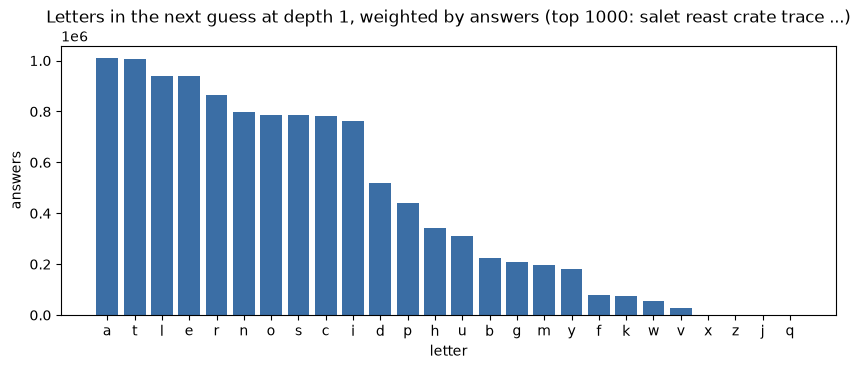

,letter,n_answers,n_positions,n_guesses,share
0,a,1008719,55920,3202,0.435782
1,t,1004653,45168,2132,0.434025
2,l,939013,39776,2192,0.405668
3,e,937957,56723,3369,0.405211
4,r,863825,45603,2581,0.373185
5,n,798353,33837,1866,0.344900
6,o,787597,35650,2314,0.340254
7,s,786650,39753,3045,0.339845
8,c,782094,31620,1450,0.337876
9,i,763743,37425,2213,0.329948


In [6]:
import string

LIVE_ONLY    = False   # <-- True: ignore positions with one answer left (guess = that answer)
COUNT_REPEATS = False  # <-- True: 'abbey' counts b twice; False: each letter once per word

words = at[~at['solved']] if LIVE_ONLY else at
_total = words['n_answers'].sum()

rows = []
for letter in string.ascii_lowercase:
    hits = words['guess'].apply(lambda w: w.count(letter) if COUNT_REPEATS else int(letter in w))
    if not hits.any():
        continue
    rows.append({'letter': letter,
                 'n_answers': int((hits * words['n_answers']).sum()),
                 'n_positions': int((hits > 0).sum()),
                 'n_guesses': words.loc[hits > 0, 'guess'].nunique()})

letter_freq = (pd.DataFrame(rows)
                 .assign(share=lambda d: d['n_answers'] / _total)
                 .sort_values('n_answers', ascending=False)
                 .reset_index(drop=True))

print(f'depth {DEPTH}: {len(letter_freq)} distinct letters over {len(words):,} positions '
      f'({_total:,} answers){" -- live positions only" if LIVE_ONLY else ""}')
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(letter_freq['letter'], letter_freq['n_answers'], color='#3b6ea5')
ax.set_ylabel('answers'); ax.set_xlabel('letter')
ax.set_title(f'Letters in the next guess at depth {DEPTH}, weighted by answers ({LABEL})')
plt.show()
display(letter_freq)

### How many letters are new

A guess's **new letters** are the distinct letters in it that none of the previous guesses
carried — how much fresh alphabet the strategy buys at this position, from 0 (every letter
already played) to 5. At `DEPTH = 0` there is no history, so it is just the opener's
distinct-letter count.

The table is the distribution over the same `words` frame: how many positions land on each
count, and how many answers they cover between them, then those answers split across the
three `guess_kind`s — so a row reads "this much fresh alphabet, bought this often, and this
often by a word that could also have won outright".

The next cell takes the other side of it — the letters that are *not* new, broken down by
what the strategy already knew about each one.

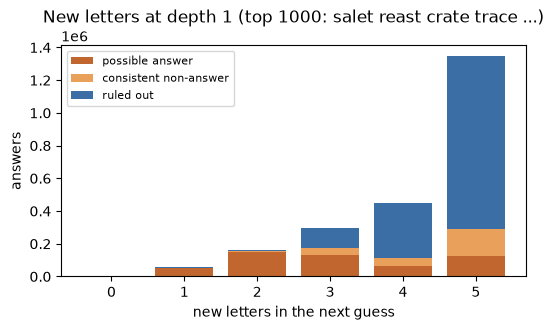

,new_letters,n_positions,n_answers,possible answer,consistent non-answer,ruled out,share
0,0,2583,3734,3717,17,0,0.001613
1,1,23707,55147,54266,356,525,0.023824
2,2,38324,164840,147898,6345,10597,0.071213
3,3,16510,295886,132976,38429,124481,0.127827
4,4,14620,450364,67068,47112,336184,0.194564
5,5,23814,1344764,125617,167362,1051785,0.580958


positions with the fewest new letters:


,opener,guesses,patterns,n_answers,guess,guess_kind,new_letters
0,trois,trois,yyybb,19,rotor,possible answer,0
1,plats,plats,byyby,17,salal,consistent non-answer,0
2,elans,elans,byyby,14,salsa,possible answer,0
3,steal,steal,byyyy,13,latte,possible answer,0
4,neals,neals,bbyyy,12,salsa,possible answer,0
5,rathe,rathe,bbyyy,11,teeth,possible answer,0
6,tepal,tepal,yybyy,10,elate,possible answer,0
7,stein,stein,byyby,9,tenet,possible answer,0
8,leapt,leapt,ybyyb,8,papal,possible answer,0
9,liard,liard,bbyyy,8,radar,possible answer,0


In [7]:
seen = words['guesses'].apply(lambda h: set(h.replace(' ', '')))
newness = words.assign(new_letters=[len(set(g) - h) for g, h in zip(words['guess'], seen)])

_by_kind = (newness.pivot_table(index='new_letters', columns='guess_kind',
                                values='n_answers', aggfunc='sum', fill_value=0)
                   .reindex(columns=list(KINDS), fill_value=0))
new_dist = (newness.groupby('new_letters')
                   .agg(n_positions=('guess', 'size'), n_answers=('n_answers', 'sum'))
                   .join(_by_kind)
                   .assign(share=lambda d: d['n_answers'] / d['n_answers'].sum())
                   .reset_index())

fig, ax = plt.subplots(figsize=(6, 3))
bottom = np.zeros(len(new_dist))
for kind, color in zip(KINDS, ('#c1662f', '#e9a05a', '#3b6ea5')):
    ax.bar(new_dist['new_letters'], new_dist[kind], bottom=bottom, color=color, label=kind)
    bottom = bottom + new_dist[kind].to_numpy()
ax.set_xlabel('new letters in the next guess'); ax.set_ylabel('answers')
ax.set_xticks(range(0, 6)); ax.legend(fontsize=8)
ax.set_title(f'New letters at depth {DEPTH} ({LABEL})')
plt.show()
display(new_dist)

print('positions with the fewest new letters:')
display(newness.sort_values(['new_letters', 'n_answers'], ascending=[True, False])
               .head(15)[['opener', 'guesses', 'patterns', 'n_answers', 'guess',
                          'guess_kind', 'new_letters']]
               .reset_index(drop=True))

### Where the repeated letters come from

The same guesses, one TILE at a time: for each of the five tiles of the next guess, what did
the history already say about that letter, and is the tile in the **same place** it said it
about? At `DEPTH = 1` the history is just the opener, so this is "what the second word does
with the first word's letters".

| role | the tile's letter... |
| --- | --- |
| `new` | appeared in no previous guess |
| `green same place` | was green, and this is that square — the confirmed letter, replayed where it belongs |
| `green elsewhere` | was green, and this is a different square |
| `yellow same place` | was yellow *at this very square* — a square the letter is known **not** to occupy |
| `yellow elsewhere` | was yellow, and this is one of the squares it might occupy |
| `grey same place` | was grey at this square, and is played there again |
| `grey elsewhere` | was grey, and is played at a different square |
| `duplicate in guess` | appeared **earlier in this same guess** |

**The rules, exactly.** A letter's known state is the best the history ever gave it: green
if it came back green anywhere, else yellow, else grey (a letter can be several at once —
a doubled letter in one guess can be yellow at one square and grey at another). `same place`
means this tile's index is one where the letter got *that* colour.

`duplicate in guess` takes precedence over everything, so the categories never overlap and
the five roles of a guess always account for the whole word — a second `l` in `rally` is
charged to the doubling, not to the `l` the opener already found. That is the reading of
"the guess just doubles a letter itself"; the per-word count below reports the same thing
without the precedence question.

Counts are **answer-weighted** the same way the letter table is: a position holding 340
answers contributes 340 to each of its five tiles, so `share` is over `5 x` the answers at
this depth and sums to 1. `n_tiles`/`n_positions` are the unweighted counts — how many tiles
and how many distinct positions. A `0` is a result, not a missing row: it says the strategy
never once does that.

**Split three ways by `guess_kind`.** Each role's answer-tiles are divided into the guess
that could win outright (`possible answer`), the one that fits every clue but is not a
mystery word so never could (`consistent non-answer`), and the one that contradicts a clue
(`ruled out`). The second table is the first normalised across the row, so it reads "when
the strategy reuses a letter this way, this is what the word doing it was". The kind is a
property of the POSITION, not the tile, so every tile of a given guess falls on the same
side of it.

Three of the roles can only ever be `ruled out`, and that is forced rather than measured:
a letter classed `grey` came back grey in *every* guess it appeared in, so the answer holds
no copies of it at all (grey means "no further copies"), and `yellow same place` puts a
letter on a square the feedback already said it does not occupy. A word doing either
contradicts a clue by construction, so it can never be a possible answer — nor even a
consistent one.

Uses the same `words` frame as the two cells above, so `LIVE_ONLY` applies here too — with
it off, the positions already down to one answer are included, and those are forced to
replay whatever the single remaining answer contains and are `possible answer` by
construction.

depth 1 (top 1000: salet reast crate trace ...): 119,558 positions, 2,314,735 answers, 11,573,675 tiles played
  possible answer        75,626 positions, 531,542 answers (22.96%)
  consistent non-answer   1,704 positions, 259,621 answers (11.22%)
  ruled out              42,228 positions, 1,523,572 answers (65.82%)


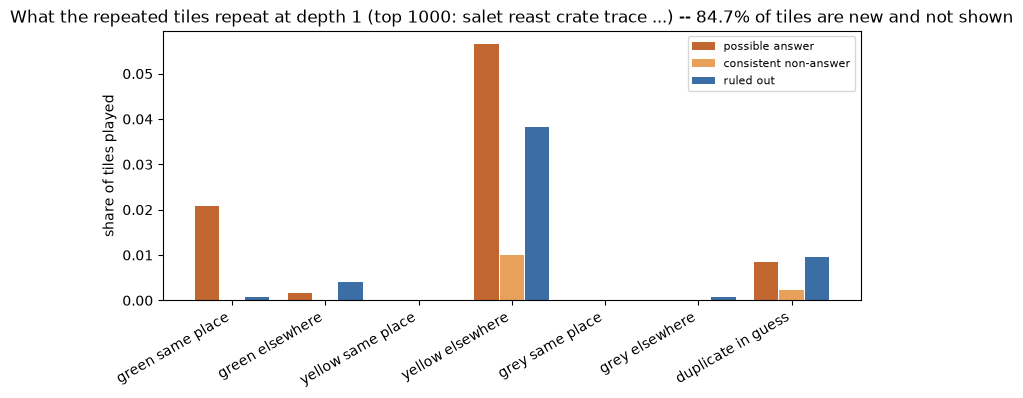

,role,n_tiles,n_positions,n_answer_tiles,possible answer,consistent non-answer,ruled out,share
0,new,327435,116975,9797761,1645347,1153591,6998823,0.846556
1,green same place,96164,60541,248697,240584,729,7384,0.021488
2,green elsewhere,9183,9069,65624,18139,146,47339,0.005670
3,yellow same place,197,195,1849,0,0,1849,0.000160
4,yellow elsewhere,142035,79754,1213466,655250,116536,441680,0.104847
5,grey same place,204,204,1690,0,0,1690,0.000146
6,grey elsewhere,932,928,8741,0,0,8741,0.000755
7,duplicate in guess,21640,20957,235847,98390,27103,110354,0.020378


...the same rows normalised across the kinds:


,possible answer,consistent non-answer,ruled out
role,,,
new,0.167931,0.117740,0.714329
green same place,0.967378,0.002931,0.029691
green elsewhere,0.276408,0.002225,0.721367
yellow same place,0.000000,0.000000,1.000000
yellow elsewhere,0.539982,0.096036,0.363982
grey same place,0.000000,0.000000,1.000000
grey elsewhere,0.000000,0.000000,1.000000
duplicate in guess,0.417177,0.114918,0.467905


the guess itself carries a doubled letter in 20,957 of 119,558 positions, 232,281 of 2,314,735 answers (10.03%)
  possible answer        95,893 answers (41.28%)
  consistent non-answer  26,945 answers (11.60%)
  ruled out              109,443 answers (47.12%)
the biggest position exercising each role, by kind:


,role,guess_kind,opener,guesses,patterns,guess,n_answers,roles
0,green same place,possible answer,crame,crame,bbgbb,slant,61,new | new | green same place | new | new
1,green same place,consistent non-answer,deans,deans,bgbbb,relet,73,new | green same place | new | duplicate in guess | new
2,green same place,ruled out,dries,dries,bgbyb,bract,44,new | green same place | new | new | new
3,green elsewhere,possible answer,drest,drest,bbbgb,slash,46,green elsewhere | new | new | duplicate in guess | new
4,green elsewhere,consistent non-answer,crust,crust,bbbgb,salse,56,green elsewhere | new | new | duplicate in guess | new
5,green elsewhere,ruled out,aloed,aloed,bbbgb,reest,100,new | green elsewhere | duplicate in guess | new | new
6,yellow same place,ruled out,sutor,sutor,ybbbb,salse,53,yellow same place | new | new | duplicate in guess | new
7,yellow elsewhere,possible answer,doest,doest,bbybb,large,310,new | new | new | new | yellow elsewhere
8,yellow elsewhere,consistent non-answer,elint,elint,ybbbb,carse,301,new | new | new | new | yellow elsewhere
9,yellow elsewhere,ruled out,eruct,eruct,yybbb,pilar,182,new | new | new | new | yellow elsewhere


In [8]:
REPEAT_ROLES = ['new', 'green same place', 'green elsewhere',
                'yellow same place', 'yellow elsewhere',
                'grey same place', 'grey elsewhere', 'duplicate in guess']


def tile_roles(guesses, patterns, guess):
    """One role per TILE of `guess`, from REPEAT_ROLES -- see the markdown above.

    `guesses`/`patterns` are the history as lists of strings. A letter's known
    state is the BEST the history ever gave it (green, else yellow, else grey);
    `same place` means this tile's index is one where the letter got that colour.
    A tile whose letter appeared EARLIER IN THIS SAME GUESS is charged to
    `duplicate in guess` whatever the history says, so the roles partition the
    word."""
    seen = {}
    for g, p in zip(guesses, patterns):
        for i, (c, tile) in enumerate(zip(g, p)):
            seen.setdefault(c, {'g': set(), 'y': set(), 'b': set()})[tile].add(i)

    roles = []
    for i, c in enumerate(guess):
        if c in guess[:i]:
            roles.append('duplicate in guess')
            continue
        where = seen.get(c)
        if where is None:
            roles.append('new')
            continue
        for tile, name in (('g', 'green'), ('y', 'yellow'), ('b', 'grey')):
            if where[tile]:
                roles.append(f'{name} same place' if i in where[tile] else f'{name} elsewhere')
                break
    return roles


roles = [tile_roles(h.split(), p.split(), g)
         for h, p, g in zip(words['guesses'], words['patterns'], words['guess'])]
_ans = words['n_answers'].to_numpy()
_kind = words['guess_kind'].to_numpy()

rows = []
for role in REPEAT_ROLES:
    per_pos = np.array([r.count(role) for r in roles])
    ans_tiles = per_pos * _ans
    row = {'role': role,
           'n_tiles': int(per_pos.sum()),
           'n_positions': int((per_pos > 0).sum()),
           'n_answer_tiles': int(ans_tiles.sum())}
    for kind in KINDS:
        row[kind] = int(ans_tiles[_kind == kind].sum())
    rows.append(row)

repeat_dist = (pd.DataFrame(rows)
                 .assign(share=lambda d: d['n_answer_tiles'] / d['n_answer_tiles'].sum()))
kind_share = (repeat_dist.set_index('role')[list(KINDS)]
                         .div(repeat_dist.set_index('role')['n_answer_tiles'], axis=0))

_tiles_played = int(_ans.sum()) * wordle.WORD_LEN
print(f'depth {DEPTH} ({LABEL}): {len(words):,} positions, {_ans.sum():,} answers, '
      f'{_tiles_played:,} tiles played'
      f'{" -- live positions only" if LIVE_ONLY else ""}')
for kind in KINDS:
    n = int(_ans[_kind == kind].sum())
    print(f'  {kind:22s} {int((_kind == kind).sum()):6,} positions, {n:6,} answers '
          f'({n / _ans.sum():6.2%})')

_repeats = repeat_dist[repeat_dist['role'] != 'new']
_new_share = float(repeat_dist.loc[repeat_dist['role'] == 'new', 'share'].iloc[0])
_x = np.arange(len(_repeats))
fig, ax = plt.subplots(figsize=(9, 3.5))
for off, (kind, color) in zip((-0.27, 0, 0.27), zip(KINDS, ('#c1662f', '#e9a05a', '#3b6ea5'))):
    ax.bar(_x + off, _repeats[kind] / _tiles_played, width=0.26, color=color, label=kind)
ax.set_xticks(_x); ax.set_xticklabels(_repeats['role'], rotation=30, ha='right')
ax.set_ylabel('share of tiles played'); ax.legend(fontsize=8)
ax.set_title(f'What the repeated tiles repeat at depth {DEPTH} ({LABEL})'
             f' -- {_new_share:.1%} of tiles are new and not shown')
plt.show()
display(repeat_dist)
print('...the same rows normalised across the kinds:')
display(kind_share)

_dup = words['guess'].apply(lambda w: len(set(w)) < wordle.WORD_LEN)
_dup_ans = int(words.loc[_dup, 'n_answers'].sum())
print(f'the guess itself carries a doubled letter in {int(_dup.sum()):,} of {len(words):,} '
      f'positions, {_dup_ans:,} of {_ans.sum():,} answers ({_dup_ans / _ans.sum():.2%})')
for kind in KINDS:
    n = int(words.loc[_dup & (words['guess_kind'] == kind), 'n_answers'].sum())
    print(f'  {kind:22s} {n:6,} answers' + (f' ({n / _dup_ans:6.2%})' if _dup_ans else ''))

roled = words.assign(roles=[' | '.join(r) for r in roles])
picks = []
for role in REPEAT_ROLES[1:]:
    hit = roled[roled['roles'].str.contains(role, regex=False)]
    for kind in KINDS:                          # the biggest of each kind
        side = hit[hit['guess_kind'] == kind]
        if side.empty:
            continue
        top = side.sort_values('n_answers', ascending=False).iloc[0]
        picks.append({'role': role, 'guess_kind': kind, 'opener': top['opener'],
                      'guesses': top['guesses'], 'patterns': top['patterns'],
                      'guess': top['guess'], 'n_answers': top['n_answers'],
                      'roles': top['roles']})

print('the biggest position exercising each role, by kind:')
with pd.option_context('display.max_colwidth', 120):
    display(pd.DataFrame(picks))

## What the guess is, by how many options remain

The same three `guess_kind`s, now against the size of the position — how many answers are
still standing when the strategy has to move. Both this section and the next work from
`scope`, which is **every position in every selected tree** by default; set `SCOPE_DEPTH` to
a number to ask the question one ply at a time instead.

`OPTION_EDGES`/`OPTION_LABELS` bin the answer count: exact for 1 to 5, where the structure is
sharpest (at 1 there is nothing to decide, at 2 it is a coin flip), then widening. They are
right-closed, so `6-10` is `6 <= n <= 10`.

**Counted by POSITIONS, not answers**, and that is deliberate here: the bucket is *defined*
by the answer count, so weighting inside it by that same count would just re-weight each
bucket by its own variable. `n_answers` is carried beside it for scale.

In [ ]:
SCOPE_DEPTH = None     # <-- None: every position of every selected tree; or a depth

OPTION_EDGES  = [0, 1, 2, 3, 4, 5, 10, 25, 50, 100, 250, np.inf]
OPTION_LABELS = ['1', '2', '3', '4', '5', '6-10', '11-25', '26-50', '51-100',
                 '101-250', '251+']

scope = pos if SCOPE_DEPTH is None else pos[pos['depth'] == SCOPE_DEPTH]
scope = scope.assign(options=pd.cut(scope['n_answers'], bins=OPTION_EDGES,
                                    labels=OPTION_LABELS, right=True))


def by_kind(frame, index, values='guess', aggfunc='size'):
    """`frame` cross-tabulated as index x guess_kind, with the row total first.

    `aggfunc='size'` counts POSITIONS; passing values='n_answers' and
    aggfunc='sum' weights by the answers sitting at them. Missing kinds come back
    as 0 columns, so the three are always present and in the same order."""
    table = (frame.pivot_table(index=index, columns='guess_kind', values=values,
                               aggfunc=aggfunc, fill_value=0, observed=False)
                  .reindex(columns=list(KINDS), fill_value=0))
    return table.assign(total=table.sum(axis=1))[['total'] + list(KINDS)]


options_dist = (by_kind(scope, 'options')
                  .rename(columns={'total': 'n_positions'})
                  .join(scope.groupby('options', observed=False)['n_answers'].sum()))
options_share = options_dist[list(KINDS)].div(options_dist['n_positions'], axis=0)

print(f'{LABEL}: {len(scope):,} positions'
      + ('' if SCOPE_DEPTH is None else f' at depth {SCOPE_DEPTH}')
      + f', {scope["n_answers"].sum():,} answers')
display(options_dist[['n_positions', 'n_answers'] + list(KINDS)])
print('...as a share of the positions in each bucket:')
display(options_share)

fig, ax = plt.subplots(figsize=(9, 3.5))
bottom = np.zeros(len(options_share))
for kind, color in zip(KINDS, ('#c1662f', '#e9a05a', '#3b6ea5')):
    ax.bar(options_share.index.astype(str), options_share[kind], bottom=bottom,
           color=color, label=kind)
    bottom = bottom + options_share[kind].to_numpy()
ax.set_xlabel('answers still possible'); ax.set_ylabel('share of positions')
ax.legend(fontsize=8); ax.tick_params(axis='x', labelrotation=30)
for lab in ax.get_xticklabels():
    lab.set_horizontalalignment('right')
ax.set_title(f'What the strategy plays, by how many options remain ({LABEL})')
plt.show()

## ...and by the greens, yellows and greys on the board

The same three kinds against what the board *looks* like — the cumulative tile composition
after the history, which is what a player can actually see. The definition is the repo's,
imported from `tools/tree_states.py` rather than restated, because a different reading is a
different table:

- **`greens`** — POSITIONS pinned green by any guess so far. A position stays pinned; a
  later guess playing another letter there does not unpin it.
- **`yellows`** — COPIES of a letter known present but not yet pinned, SUMMED over letters.
  Two loose B's count 2, and a letter with one copy green and another loose contributes 1.
- **`grays`** — `5 - greens - yellows`.

That reading is the one that makes `greens + yellows` the ANSWER SLOTS ACCOUNTED FOR, hence
`grays` exactly the slots still blank — asserted below at every position. **21 compositions
occur, not 20**: `(4 green, 1 yellow)` is impossible as a single reply but perfectly
reachable cumulatively.

**Weighted by ANSWERS**, matching `tree_states.py`: a position holding `n` answers
contributes `n` cases, so a share reads "this fraction of the answers sitting on a board
that looks like this". `n_positions` is carried beside it, so the node-weighted reading
stays recoverable.

> **With `SCOPE_DEPTH = None` the denominator is not the 2,315.** An answer sits in a
> position at every level it survives, so pooling counts it once per surviving turn and
> these cells are answer-weighted BOARD STATES. Set `SCOPE_DEPTH` to a ply for the reading
> where each answer appears at most once.

In [ ]:
def composition(guesses, patterns):
    """(greens, yellows, grays) after a history -- tree_states' definition, imported."""
    state = tree_states.EMPTY
    for g, p in zip(guesses, patterns):
        state = tree_states.apply_row(state, g, p)
    greens, yellows = tree_states.greens_yellows(state)
    return greens, yellows, wordle.WORD_LEN - greens - yellows


_comp = [composition(h.split(), p.split())
         for h, p in zip(scope['guesses'], scope['patterns'])]
if any(c[2] < 0 for c in _comp):
    raise ValueError('greens + yellows exceeded the word length: the slots accounted for '
                     'cannot outnumber the squares')

board = scope.assign(greens=[c[0] for c in _comp],
                     yellows=[c[1] for c in _comp],
                     grays=[c[2] for c in _comp])

comp_dist = (by_kind(board, ['greens', 'yellows', 'grays'],
                     values='n_answers', aggfunc='sum')
               .rename(columns={'total': 'n_answers'})
               .join(board.groupby(['greens', 'yellows', 'grays']).size()
                          .rename('n_positions')))
comp_share = comp_dist[list(KINDS)].div(comp_dist['n_answers'], axis=0)

print(f'{LABEL}: {len(comp_dist)} compositions over {len(board):,} positions'
      + ('' if SCOPE_DEPTH is None else f' at depth {SCOPE_DEPTH}')
      + f', {board["n_answers"].sum():,} answer-positions')
display(comp_dist[['n_positions', 'n_answers'] + list(KINDS)])
print('...as a share of the answers on each board:')
display(comp_share)

_labels = [f'{g}g {y}y {b}b' for g, y, b in comp_share.index]
fig, ax = plt.subplots(figsize=(11, 3.5))
bottom = np.zeros(len(comp_share))
for kind, color in zip(KINDS, ('#c1662f', '#e9a05a', '#3b6ea5')):
    ax.bar(_labels, comp_share[kind], bottom=bottom, color=color, label=kind)
    bottom = bottom + comp_share[kind].to_numpy()
ax.set_xlabel('greens / yellows / greys showing'); ax.set_ylabel('share of answers')
ax.legend(fontsize=8); ax.tick_params(axis='x', labelrotation=45)
for lab in ax.get_xticklabels():
    lab.set_horizontalalignment('right')
ax.set_title(f'What the strategy plays, by what the board shows ({LABEL})')
plt.show()

print('the compositions where the strategy most often plays a probe:')
display(comp_dist.assign(probe_share=comp_share[KIND_RULED_OUT])
                 .sort_values('probe_share', ascending=False)
                 .head(10)[['n_positions', 'n_answers', 'probe_share']])

## Look up one position

Filter by the history you have in hand — it is just a prefix of the `guesses`/`patterns`
columns. Each selected tree that reaches that history gets its own block: the position
itself, then every outcome its optimal next guess can produce from there. An empty
`HISTORY`/`FEEDBACK` is the root, so it prints one block per tree.

In [9]:
HISTORY  = 'salet'     # <-- guesses so far, space separated ('' for the root)
FEEDBACK = 'bbbyb'     # <-- their feedback, space separated `byg` strings ('' for the root)

hits = pos[(pos['guesses'] == HISTORY) & (pos['patterns'] == FEEDBACK)]
if hits.empty:
    print(f'no position with guesses {HISTORY!r} and patterns {FEEDBACK!r} in any of '
          f'{len(TREE_OPENERS)} tree(s) ({LABEL}) -- unreachable under these strategies, '
          f'or a typo')
for _, r in hits.iterrows():
    print(f'{r["opener"]}: {r["n_answers"]:,} answers left; '
          f'optimal next guess: {r["guess"]!r}')
    display(hits[hits['opener'] == r['opener']].reset_index(drop=True))
    kids = pos[(pos['opener'] == r['opener'])
               & (pos['guesses'] == (HISTORY + ' ' + r['guess']).strip())]
    print(f'{len(kids)} outcome(s) of {r["guess"]!r} here:')
    display(kids.reset_index(drop=True))

salet: 165 answers left; optimal next guess: 'drone'


,opener,depth,guesses,patterns,n_answers,guess,guess_kind,solved,sample
0,salet,1,salet,bbbyb,165,drone,possible answer,False,beech beefy begin begun


57 outcome(s) of 'drone' here:


,opener,depth,guesses,patterns,n_answers,guess,guess_kind,solved,sample
0,salet,2,salet drone,bbbyb bbbyg,12,finch,ruled out,False,binge fence genie hence
1,salet,2,salet drone,bbbyb bybby,12,femur,possible answer,False,berry every femur ferry
2,salet,2,salet drone,bbbyb bybbg,10,merge,possible answer,False,curve eerie fibre merge
3,salet,2,salet drone,bbbyb bbbbg,9,piece,possible answer,False,chime femme fugue imbue
4,salet,2,salet drone,bbbyb bgbbg,9,campi,ruled out,False,bribe creme crepe crime
5,salet,2,salet drone,bbbyb bbbyy,8,begin,possible answer,False,begin begun bench enemy
6,salet,2,salet drone,bbbyb ybbbg,8,bijou,ruled out,False,budge chide fudge guide
7,salet,2,salet drone,bbbyb bbbby,6,beech,possible answer,False,beech beefy check equip
8,salet,2,salet drone,bbbyb byybg,6,forge,possible answer,False,force forge gorge ombre
9,salet,2,salet drone,bbbyb bggbg,6,probe,possible answer,False,broke froze grope grove


## Cross-check the counts

`n_answers` is read off the tree's structure (lines sharing a prefix). This re-derives it
from scratch for a random sample of positions — filtering the 2315 answers by replaying
each guess/feedback pair through `wordle.pattern` — so a misparse shows up as a mismatch
rather than as a plausible-looking wrong number. Same spirit as `tools/checktrees.py`. The
same filter re-derives `guess_kind`'s first case for free: the guess could win here exactly
when it is one of the survivors. The sample is drawn across every selected tree at once,
since a history already names the tree it belongs to.

The `consistent non-answer` / `ruled out` half of `guess_kind` is checked in `positions()`
itself, at *every* node rather than a sample: being one of the node's answers has to agree
with (reproduces every clue) and (is an answer word), and the function raises if it does not.

In [ ]:
N_CHECK = 200      # <-- how many random positions to re-derive

def answers_after(guesses, patterns):
    """The answers consistent with a history, from the feedback function alone."""
    alive = list(ANSWERS)
    for g, p in zip(guesses, patterns):
        want = tree_states.code_of(p)
        alive = [a for a in alive if wordle.pattern(g, a) == want]
    return alive

rng = np.random.default_rng(0)                       # reproducible sample
idx = rng.choice(len(pos), size=min(N_CHECK, len(pos)), replace=False)
bad = []
for i in idx:
    r = pos.iloc[int(i)]
    alive = answers_after(r['guesses'].split(), r['patterns'].split())
    if len(alive) != r['n_answers']:
        bad.append((r, f'{r["n_answers"]} answers on the tree, {len(alive)} by filtering'))
    # ...and the same filter re-derives the FIRST kind: the guess could win here
    # exactly when it survives as one of the answers.
    elif (r['guess'] in alive) != (r['guess_kind'] == KIND_ANSWER):
        bad.append((r, f'kind {r["guess_kind"]!r} but the guess is '
                       f'{"" if r["guess"] in alive else "not "}one of the survivors'))

print(f'checked {len(idx)} positions over {pos.iloc[idx]["opener"].nunique()} tree(s) '
      f'({LABEL}): ' + ('all counts and kinds agree' if not bad
                        else f'{len(bad)} MISMATCH(ES)'))
for r, why in bad[:10]:
    print(f'  {r["opener"]}: {r["guesses"]} | {r["patterns"]} -> {r["guess"]}: {why}')